In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

Layer 0 min target rank for >= 50% cumulative energy: 62


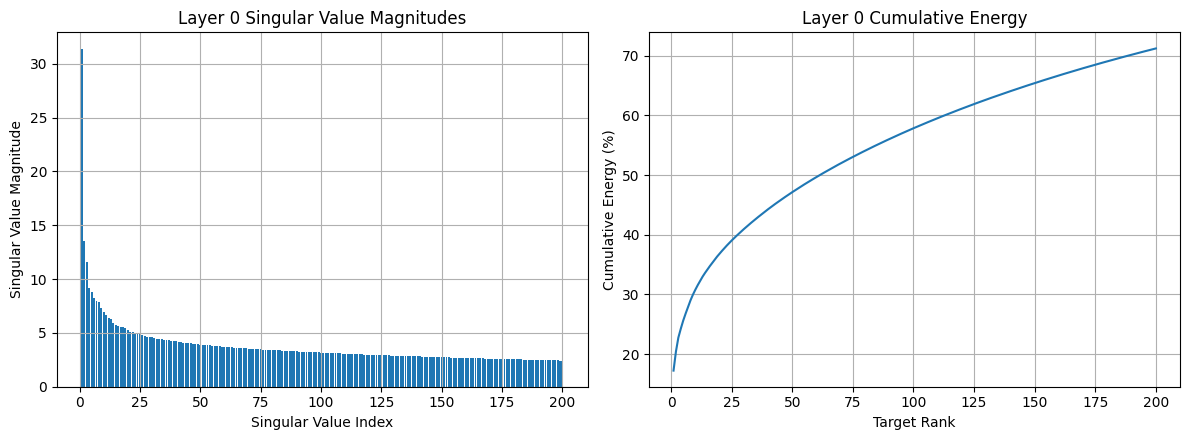

Layer 7 min target rank for >= 50% cumulative energy: 120


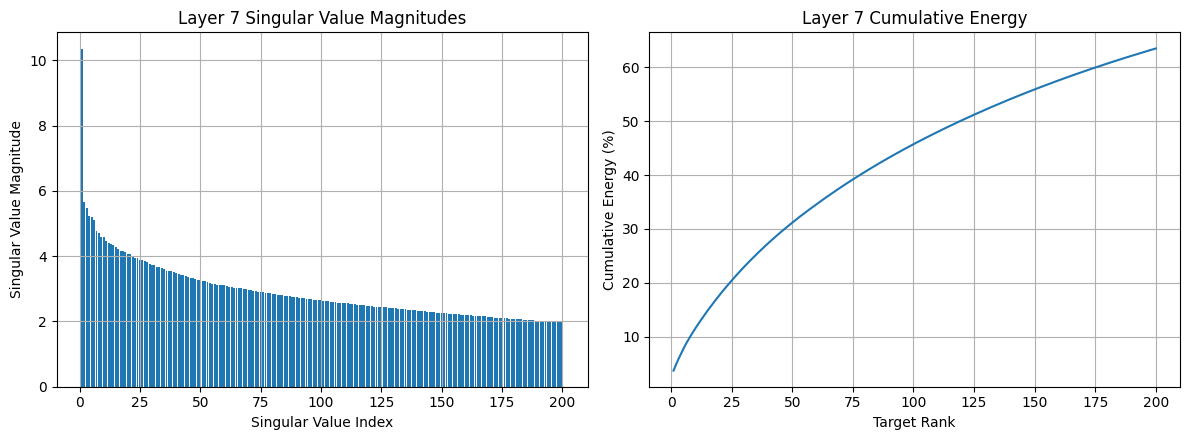

Layer 15 min target rank for >= 50% cumulative energy: 84


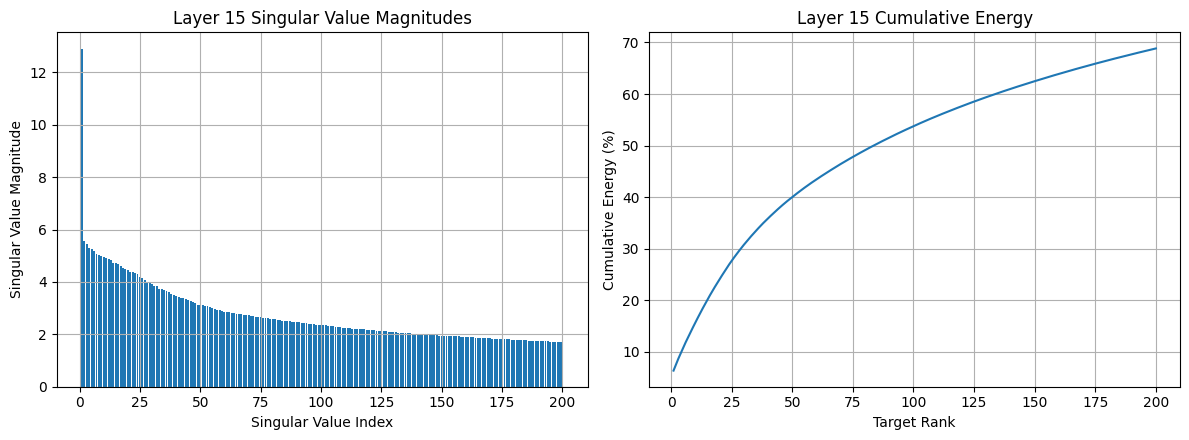

In [11]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""

target_layers = [0, 7, 15]
num_of_visual = 200 
x_axis = range(1, num_of_visual + 1)

for k in target_layers:
    # Analyze the weights of the query projection layer (q_proj) where layer = k
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach().to("cuda") 

    # Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

    # Compute the retained energy ratio (Cumulative energy) of each singular value.
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    # 4b
    min_rank = torch.nonzero(energy_ratios >= 50.0, as_tuple = True)[0][0].item() + 1

    print(f"Layer {k} min target rank for >= 50% cumulative energy: {min_rank}")

    # extract first 200 singular values, convert to CPU numpy
    singular_values_first_200 = S[:num_of_visual].cpu().numpy()
    energy_first_200 = energy_ratios[:num_of_visual].cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize = (12, 4.5))

    # plot singular value magnitude bar chart
    axes[0].bar(x_axis, singular_values_first_200)
    axes[0].set_xlabel('Singular Value Index')
    axes[0].set_ylabel('Singular Value Magnitude')
    axes[0].set_title(f'Layer {k} Singular Value Magnitudes')
    axes[0].grid(True)

    # plot cumulative energy line chart
    axes[1].plot(x_axis, energy_first_200)
    axes[1].set_xlabel('Target Rank')
    axes[1].set_ylabel('Cumulative Energy (%)')
    axes[1].set_title(f'Layer {k} Cumulative Energy')
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.savefig(f"layer {k} svd charts.png", dpi = 300)
    plt.show()
